# Task 1 — Dự báo nhiệt độ dầu trước 2 giờ

Dùng 48 giờ quan sát để dự đoán một giá trị OT tại **t+2**.

Đã có test độc lập cho cấu hình cuối với **3 seed: 42, 123, 2026**.

Notebook trình bày dữ liệu, kiến trúc và kết quả đã đo. `TRAIN=False` xem lại kết quả, không tự huấn luyện lại.

## Chuẩn bị

Dùng PyTorch cho model; pandas và matplotlib để xem dữ liệu. Các hàm đọc kết quả và vận hành được để trong helper như notebook M1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd()/"src/utils.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/"src"))
from notebook_support import (
    load_run, setup_plots, layer_shapes, load_weights, training_settings,
    validation_comparison, prepare_training, train_presented_model
)

setup_plots()
torch.set_num_threads(2)
TRAIN = False
TASK = "task1"
run = load_run(TASK, architecture="legacy")
settings = run["config"]
torch.manual_seed(settings["seed"])

## 1. Đọc và kiểm tra dữ liệu

**ETTh1:** 17.420 quan sát theo giờ, 7 biến số. `OT` là biến cần dự đoán; sáu biến còn lại là các phép đo tải điện. Dữ liệu được giữ đúng thứ tự thời gian.

In [2]:
data = pd.read_csv(ROOT/"data/raw/etth1/ETTh1.csv", parse_dates=["date"])
display(data.head())
print("Số quan sát:", len(data))
print("Khoảng thời gian:", data.date.min(), "→", data.date.max())
print("Giá trị thiếu:", data.isna().sum().sum())
print("Timestamp trùng:", data.date.duplicated().sum())
print("Khoảng cách thời gian:", data.date.diff().dropna().unique())

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


Số quan sát: 17420
Khoảng thời gian: 2016-07-01 00:00:00 → 2018-06-26 19:00:00
Giá trị thiếu: 0
Timestamp trùng: 0
Khoảng cách thời gian: <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[us]


## 2. EDA trên tập train

Chỉ dùng 70% đầu để tìm hiểu phân bố, tương quan và độ trễ. Các nhận xét này tạo giả thuyết; quyết định giữ cải tiến phải dựa trên validation.

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,12194.00,12194.00,12194.00,12194.00,12194.00,12194.00,12194.00
mean,7.44,1.96,4.55,0.69,2.92,0.78,16.29
std,6.35,2.11,6.16,1.93,1.19,0.66,8.35
min,-19.62,-4.76,-21.96,-5.93,-1.19,-1.37,-4.08
25%,5.96,0.34,3.59,-0.71,2.16,0.64,10.06
50%,8.44,1.81,5.83,0.71,2.68,0.94,15.12
75%,11.12,3.42,8.24,2.17,3.35,1.19,20.68
max,23.64,10.11,17.34,7.57,8.50,3.05,46.01


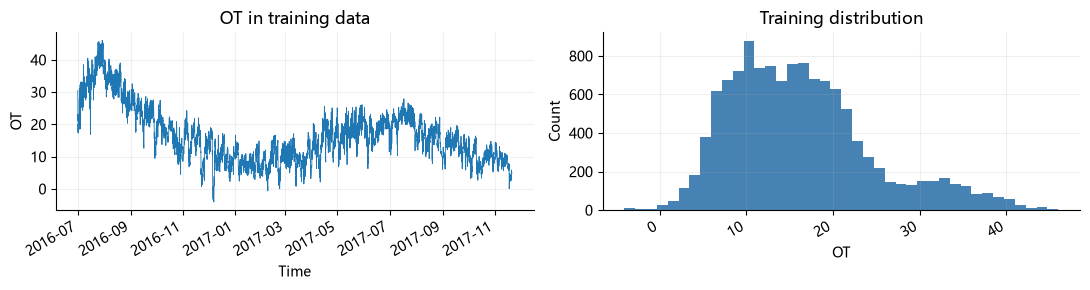

In [3]:
train_end = int(len(data) * 0.70)
validation_end = int(len(data) * 0.85)
train_data = data.iloc[:train_end]
display(train_data.drop(columns="date").describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(train_data.date, train_data.OT, linewidth=0.6)
axes[0].set(title="OT in training data", xlabel="Time", ylabel="OT")
axes[1].hist(train_data.OT, bins=40, color="steelblue")
axes[1].set(title="Training distribution", xlabel="OT", ylabel="Count")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

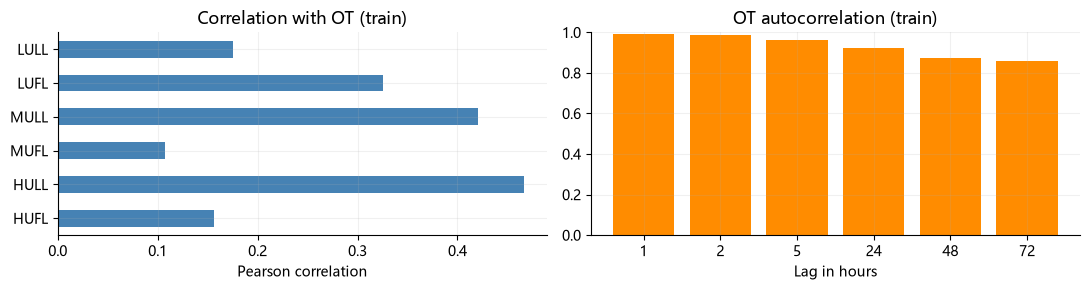

,Lag (giờ),Autocorrelation
0,1,0.993
1,2,0.985
2,5,0.963
3,24,0.925
4,48,0.876
5,72,0.857


In [4]:
correlations = train_data.drop(columns="date").corr()["OT"].drop("OT")
lags = [1, 2, 5, 24, 48, 72]
autocorrelation = [train_data.OT.autocorr(lag) for lag in lags]

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
correlations.plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Correlation with OT (train)", xlabel="Pearson correlation")
axes[1].bar([str(lag) for lag in lags], autocorrelation, color="darkorange")
axes[1].set(title="OT autocorrelation (train)", xlabel="Lag in hours", ylim=(0, 1))
plt.tight_layout()
plt.show()
display(pd.DataFrame({"Lag (giờ)": lags, "Autocorrelation": autocorrelation}).round(3))

**Ý nghĩa cho mô hình:** OT gần đây là baseline mạnh, vì vậy cần so với persistence. Tự tương quan ở độ trễ dài có thể do cả xu hướng chậm; chưa đủ để kết luận có chu kỳ 24 giờ. Các hướng kiểm tra là input 24/48/72 giờ, OT đơn lẻ so với nhiều biến, và dự báo phần thay đổi (residual). Không coi các hướng chưa chạy là đã cải thiện điểm.

## 3. Chia dữ liệu và tạo cửa sổ

Chia 70% / 15% / 15% theo thời gian. Scaler chỉ fit train; mỗi cửa sổ nằm trọn trong một tập. Input có 48 giờ × 7 biến. `t` là timestamp cuối đã quan sát.

In [5]:
from utils import prepare_forecast
parts, scalers, horizons, identity = prepare_forecast(TASK, settings)
partitions = [data.iloc[:train_end], data.iloc[train_end:validation_end],
              data.iloc[validation_end:]]
split_table = []
for split, frame in zip(["train", "validation", "test"], partitions):
    split_table.append({"Tập": split, "Dòng gốc": len(frame),
                        "Từ": frame.date.iloc[0], "Đến": frame.date.iloc[-1],
                        "X shape": str(parts[split]["X"].shape),
                        "y shape": str(parts[split]["y"].shape)})
display(pd.DataFrame(split_table))
origin = pd.Timestamp(parts["train"]["origins"][0])
display(pd.DataFrame({"Horizon": horizons,
                      "Quan sát cuối t": origin,
                      "Target timestamp": parts["train"]["targets"][0]}))

,Tập,Dòng gốc,Từ,Đến,X shape,y shape
0,train,12194,2016-07-01 00:00:00,2017-11-21 01:00:00,"(12145, 48, 7)","(12145, 1)"
1,validation,2613,2017-11-21 02:00:00,2018-03-09 22:00:00,"(2564, 48, 7)","(2564, 1)"
2,test,2613,2018-03-09 23:00:00,2018-06-26 19:00:00,"(2564, 48, 7)","(2564, 1)"


,Horizon,Quan sát cuối t,Target timestamp
0,2,2016-07-02 23:00:00,2016-07-03 01:00:00


Ví dụ chỉ số: nếu input kết thúc tại 23:00, Task 1 dự đoán 01:00 ngày sau; Task 2 dự đoán lần lượt 00:00–04:00. Nhãn dự báo không xuất hiện trong input. Helper dùng StandardScaler: trừ trung bình train rồi chia độ lệch chuẩn train; metric cuối được đưa về thang OT gốc.

## 4. Xây dựng mô hình

`B` là batch size, `H` là hidden size. Dùng cùng dot-product attention: query so với các trạng thái đầu vào, softmax tạo trọng số, rồi lấy tổng có trọng số. Đây là một attention head, không phải MultiHeadAttention.

In [6]:
def dot_attention(query, memory):
    # query [B, outputs, H]; memory [B, input_positions, H].
    scores = torch.bmm(query, memory.transpose(1, 2)) / np.sqrt(memory.shape[-1])
    weights = scores.softmax(dim=-1)
    return torch.bmm(weights, memory), weights

**Luồng:** `[B,48,7]` → LSTM → memory `[B,48,128]` → attention từ trạng thái cuối → concat `[B,256]` → Linear → cộng OT cuối → `[B,1]`. Residual học mức thay đổi, không dùng OT tương lai.

In [7]:
class ForecastRNN(nn.Module):
    def __init__(self, features, config):
        super().__init__()
        h = config["hidden_size"]
        self.attention = config["attention"]
        self.residual = config["residual"]
        if config["cell"] == "LSTM":
            self.rnn = nn.LSTM(features, h, batch_first=True)
        else:
            self.rnn = nn.RNN(features, h, batch_first=True)
        self.dropout = nn.Dropout(config["dropout"])
        self.output = nn.Linear(2*h if self.attention else h, 1)
        if self.residual:
            nn.init.zeros_(self.output.weight)
            nn.init.zeros_(self.output.bias)

    def forward(self, X, last):
        states, _ = self.rnn(X)                  # [batch, 48, hidden]
        summary = states[:, -1]                 # last observed state
        if self.attention:
            context, _ = dot_attention(summary[:, None], states)
            summary = torch.cat([summary, context[:, 0]], dim=-1)
        prediction = self.output(self.dropout(summary))
        if self.residual:
            prediction = prediction + last[:, None]
        return prediction

In [8]:
model = ForecastRNN(len(scalers["features"]), settings)
if not TRAIN:
    load_weights(model, run)
X_example = torch.from_numpy(parts["validation"]["X"][:2])
last_example = torch.from_numpy(parts["validation"]["last"][:2])
layers, prediction = layer_shapes(model, X_example, last_example)
print(model)
display(layers)
print("Output:", tuple(prediction.shape))
print("Số tham số:", sum(p.numel() for p in model.parameters()))

ForecastRNN(
  (rnn): LSTM(7, 128, batch_first=True)
  (dropout): Dropout(p=0.0, inplace=False)
  (output): Linear(in_features=256, out_features=1, bias=True)
)


,Layer,Input,Output,Parameters
0,rnn (LSTM),"(2, 48, 7)","(2, 48, 128)",70144
1,dropout (Dropout),"(2, 256)","(2, 256)",0
2,output (Linear),"(2, 256)","(2, 1)",257


Output: (2, 1)
Số tham số: 70401


Bảng trên là shape đi qua **layer thật** trên hai mẫu, không phải bảng shape viết tay. Attention, phép lấy trung bình và cộng residual là phép toán trong `forward`, nên cần đọc cùng sơ đồ và code phía trên.

## 5. Loss và huấn luyện

Thông số bên dưới thuộc run đã đo, không phải cấu hình recovery mới. Checkpoint được chọn bằng validation, không lấy epoch cuối một cách mặc định.

In [9]:
display(training_settings(run))

,Thông số,Giá trị
0,Seed,42.000
1,Hidden size,128.000
2,Batch run này,64.000
3,Learning rate ban đầu,0.001
4,Epoch tối đa,60.000
5,Early-stopping patience,8.000
6,Epoch đã chạy,14.000
7,Epoch checkpoint tốt nhất,6.000
8,Thời gian train (giây),15.120
9,Số tham số,70401.000


MSE trên OT đã chuẩn hóa. Khi đánh giá, inverse scale để tính sai số ở đơn vị gốc.

Hàm dưới đây là một bước cập nhật **được dùng trong vòng lặp train thật** của project. Ô này chỉ định nghĩa hàm, không tự train.

In [10]:
def forecast_train_step(model, optimizer, X, y, last):
    optimizer.zero_grad(set_to_none=True)
    prediction = model(X, last)
    loss = nn.functional.mse_loss(prediction, y)
    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite forecasting training loss")
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.)
    optimizer.step()
    return loss.item()

In [11]:
if TRAIN:
    model = prepare_training(model, settings["seed"])
optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"])
print("Adam — learning rate ban đầu:", settings["learning_rate"])

Adam — learning rate ban đầu: 0.001


In [12]:
if TRAIN:
    run = train_presented_model(TASK, model, optimizer, settings, parts=parts, scalers=scalers)
    display(training_settings(run))
history = run["history"]

history_columns = ['epoch', 'train_loss', 'val_RMSE', 'lr']
display(history[history_columns].tail(5).round(4))

,epoch,train_loss,val_RMSE,lr
9,10,0.0222,0.8380,0.0010
10,11,0.0215,0.8557,0.0005
11,12,0.0211,0.8198,0.0005
12,13,0.0210,0.8336,0.0005
13,14,0.0207,0.8131,0.0005


## 6. Validation và lựa chọn cấu hình

So sánh ở seed 42 trước, chọn bằng validation. Chỉ cấu hình cuối mới được lặp thêm seed; không chọn seed theo điểm test. Learning curve dưới đây là run được phân tích ở trên.

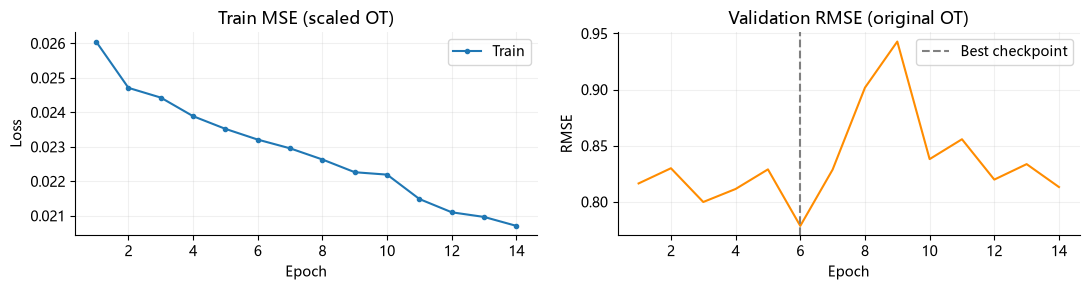

,Cấu hình,Validation RMSE,Được chọn
0,rnn64,0.9622,False
1,lstm64,0.9336,False
2,lstm64_attention,0.8177,False
3,lstm64_residual,0.8111,False
4,lstm64_attention_residual,0.7818,False
5,lstm128_attention_residual,0.7785,True
6,lstm64_attention_residual_OT,0.7854,False


In [13]:
best_epoch = run["metadata"]["best_epoch"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(history.epoch, history.train_loss, marker="o", markersize=3, label="Train")
axes[0].set(xlabel="Epoch", ylabel="Loss")

axes[0].set_title("Train MSE (scaled OT)")
axes[1].plot(history.epoch, history.val_RMSE, color="darkorange")
axes[1].set(title="Validation RMSE (original OT)", xlabel="Epoch", ylabel="RMSE")

axes[0].legend()
axes[1].axvline(best_epoch, linestyle="--", color="grey", label="Best checkpoint")
axes[1].legend()
plt.tight_layout()
plt.show()
display(validation_comparison(TASK))

MSE train và RMSE validation có thang đo khác nhau nên vẽ hai trục riêng. So sánh RNN, LSTM, attention và residual giúp thấy phần nào tạo cải thiện. Cấu hình cuối có H=128; không dùng test để chọn lại lookback hoặc model.

## 7. Benchmark test cuối

**R²/NSE càng cao càng tốt; MAE/RMSE càng thấp càng tốt.** R² là hệ số xác định, không phải phần trăm accuracy. R² và NSE dùng cùng công thức residual nên bằng nhau. Bảng chính dùng mean ± sample std của đúng ba seed; baseline là công thức xác định, không phải ba model đã train.

In [14]:
from notebook_support import forecast_benchmark, benchmark_tables
benchmark = forecast_benchmark(TASK)
final_table, seed_table, improvement = benchmark_tables(benchmark)
display(final_table)
display(seed_table)
print(f"Giảm RMSE so với persistence: {improvement:.2f}%")
print("Mục tiêu trong plan: giảm ít nhất 5% —", "ĐẠT" if improvement >= 5 else "CHƯA ĐẠT")

,Mô hình,R2,NSE,MAE,RMSE
0,Persistence,0.8895,0.8895,0.6474,0.9448
1,Daily seasonal,0.3573,0.3573,1.7060,2.2792
2,Model — mean ± std (3 seed),0.9113 ± 0.0017,0.9113 ± 0.0017,0.5707 ± 0.0084,0.8468 ± 0.0079


,R2,NSE,MAE,RMSE
seed,,,,
42,0.9103,0.9103,0.5775,0.8513
123,0.9103,0.9103,0.5731,0.8514
2026,0.9132,0.9132,0.5614,0.8377


Giảm RMSE so với persistence: 10.38%
Mục tiêu trong plan: giảm ít nhất 5% — ĐẠT


## 8. Xem dự đoán và sai số

Hình dùng 240 dự đoán test đầu tiên theo thời gian của seed 42, không chọn các đoạn đẹp. Bảng nhỏ hiển thị target timestamp và sai số thực tế.

,target_time,horizon,actual,predicted,absolute_error
0,2018-03-12 00:00:00,2,8.020,7.3258,0.6942
1,2018-03-12 01:00:00,2,7.949,7.3912,0.5578
2,2018-03-12 02:00:00,2,7.597,7.7828,0.1858
3,2018-03-12 03:00:00,2,7.668,7.6406,0.0274
4,2018-03-12 04:00:00,2,7.949,7.2532,0.6958


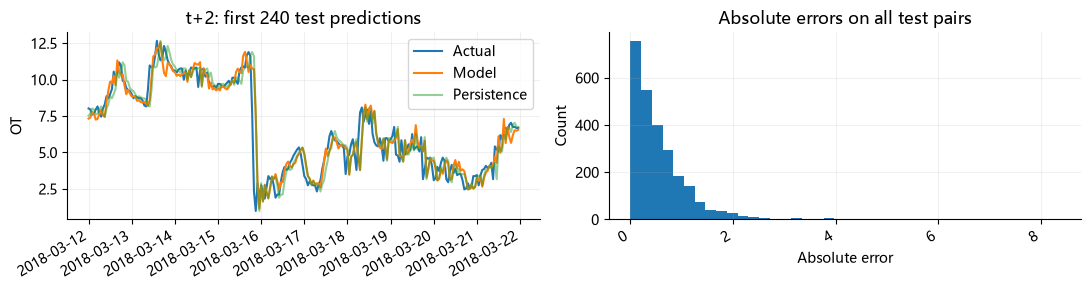

In [15]:
predictions = run["predictions"].copy()
predictions["target_time"] = pd.to_datetime(predictions.target_time)
predictions["absolute_error"] = abs(predictions.actual-predictions.predicted)
columns = ["target_time", "horizon", "actual", "predicted", "absolute_error"]
display(predictions[columns].head().round({"actual": 4, "predicted": 4, "absolute_error": 4}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
values = predictions.head(240)
axes[0].plot(values.target_time, values.actual, label="Actual")
axes[0].plot(values.target_time, values.predicted, label="Model")
axes[0].plot(values.target_time, values.persistence, label="Persistence", alpha=.5)
axes[0].set(title="t+2: first 240 test predictions", ylabel="OT")
axes[0].legend()
axes[1].hist(predictions.absolute_error, bins=40)
axes[1].set(title="Absolute errors on all test pairs", xlabel="Absolute error", ylabel="Count")
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

## 9. Đánh giá kết quả

Test **R²=0,9113**, **RMSE=0,8468 ± 0,0079**; giảm RMSE **10,38%** so với persistence. Kết quả đạt mục tiêu cải thiện 5% của plan, không phải điểm thấp trong phép so sánh này. Điều đó không khẳng định model tốt nhất trên mọi cách chia ETTh1.

Các hướng chưa chạy như lookback 24/72 giờ vẫn là đề xuất. Những thay đổi tiếp theo phải chọn bằng validation mới; không tinh chỉnh theo test đã xem.

### Nguồn

[ETDataset — tác giả công bố ETTh1](https://github.com/zhouhaoyi/ETDataset). Notebook dùng cách chia 70/15/15 đã ghi trong plan; đây là benchmark nội bộ của project, không tự nhận là cùng giao thức của mọi bài báo. Chi tiết dữ liệu: [data/raw/README.md](../data/raw/README.md).